# 981. Time Based Key-Value Store
**Difficulty:** 🟡 Medium · **Topic:** Binary Search · **Pattern:** [Sorted Search](README.md) · **LeetCode:** https://leetcode.com/problems/time-based-key-value-store/

## 💡 Concepts

**Core concept(s):** **Hash map of sorted lists + binary search for "the last entry `<= t`"**.

**Why it applies here:**
- Each key has its own history of `(timestamp, value)` pairs, so a hash map from key → history list gives `O(1)` access to the right history.
- The problem guarantees `set` timestamps are **strictly increasing**, so appending keeps every history list **sorted by time** for free.
- `get(key, t)` asks for the value with the **largest timestamp `<= t`** — a boundary in a sorted list, which binary search finds in `O(log n)`.

**Key intuition:**
- Think of each key's history as a timeline: `[(1, "bar"), (4, "bar2")]`.
- `get("foo", 3)` means "what was the value at time 3?": the last change at or before time 3, which is `(1, "bar")`.
- Binary search keeps a **candidate**: whenever `times[mid] <= t`, `mid` is a valid answer, so remember it and look further **right** for a later one.

---

### 📚 What is a Hash Map?
- A hash map (Python `dict`) stores key → value pairs.
- It hashes each key to a slot in an array, so it jumps straight to the value instead of scanning.
- Insert, lookup, and delete are **`O(1)` on average**.
- **In Python:** `dict`; `collections.defaultdict(list)` creates an empty list the first time a key is used.
- **Why it matters here:** it separates the histories, so `get("foo", ...)` never looks at `"bar"`'s entries.

### 📚 What is Binary Search (boundary form)?
- Classic **binary search** halves a sorted search space `[lo, hi]` until it finds the target or the space is empty.
- The **boundary form** answers "the **last** index whose value is `<= t`" instead of "where is `t` exactly?".
- **How it works:** if `times[mid] <= t`, record `mid` as the best so far and continue in the right half (`lo = mid + 1`); otherwise the answer is in the left half (`hi = mid - 1`). When the space empties, the recorded candidate is the answer (or there is none).
- **Complexity:** `O(log n)` time, `O(1)` extra space.
- **In Python:** by hand as below, or `bisect.bisect_right(times, t) - 1` (index of the last time `<= t`, `-1` if none).

### 📚 What is a Design Problem (class with operations)?
- LeetCode "design" problems ask for a **class** whose methods are called in sequence.
- Tests are given as two lists: operation names (`["TimeMap", "set", "get", ...]`) and their arguments; the expected output has `None` for calls that return nothing.
- The complexity of interest is **per operation**: here `set` is `O(1)` and `get` is `O(log n)`, where `n` is the number of entries for that key.

---

**Prerequisite knowledge:**
- The classic binary search loop (see [Binary Search](binary_search.ipynb)).
- Python classes and `__init__`.

## 📝 Problem

Design a time-based key-value store `TimeMap`:
- `TimeMap()` — create an empty store.
- `set(key, value, timestamp)` — store `value` for `key` at time `timestamp`.
- `get(key, timestamp)` — return the value whose stored timestamp is the **largest one `<= timestamp`**. If there is none (unknown key, or every stored time is later), return `""`.

**Example**
```
ops  = ["TimeMap", "set",              "get",      "get",      "set",               "get",      "get"]
args = [[],        ["foo", "bar", 1],  ["foo", 1], ["foo", 3], ["foo", "bar2", 4],  ["foo", 4], ["foo", 5]]
out  = [None,      None,               "bar",      "bar",      None,                "bar2",     "bar2"]

history of "foo":  (1, "bar")  (4, "bar2")
get at t = 3  ->  last time <= 3 is 1  ->  "bar"
get at t = 5  ->  last time <= 5 is 4  ->  "bar2"
```

**Constraints:** `1 <= key.length, value.length <= 100`; `1 <= timestamp <= 10⁷`; all `set` timestamps are **strictly increasing**; at most `2·10⁵` calls in total.

> Two approaches: scan a key's whole history on every `get` (`O(n)` per call), and binary search the sorted history (`O(log n)` per call, the pattern template). Both store the data the same way; only `get` differs.

In [1]:
from typing import List, Optional
from collections import defaultdict
import random


def run_ops(cls, ops: List[str], args: List[list]) -> list:
    """Replay a LeetCode-style design test: ops[0] constructs, the rest are method calls."""
    obj, out = None, []
    for op, a in zip(ops, args):
        if op == cls.LEETCODE_NAME:
            obj = cls(*a)
            out.append(None)                  # the constructor returns nothing
        else:
            out.append(getattr(obj, op)(*a))  # set -> None, get -> a string
    return out

### Approach 1 — Brute Force: scan the whole history on every `get`

**Idea:**
1. `set`: append `(timestamp, value)` to the key's list — `O(1)`.
2. `get`: walk the key's whole list and keep the value of the last entry whose time is `<= t`. (The list is sorted, but this approach ignores that.)

**Time complexity:** `set` `O(1)`; `get` `O(n)` — it reads all `n` entries stored for the key.

**Space complexity:** `O(N)` for all `N` stored pairs; `get` uses `O(1)` extra.

In [2]:
class TimeMapBrute:
    LEETCODE_NAME = "TimeMap"

    def __init__(self):
        self.store = defaultdict(list)            # key -> [(timestamp, value), ...] in set() order

    def set(self, key: str, value: str, timestamp: int) -> None:
        self.store[key].append((timestamp, value))

    def get(self, key: str, timestamp: int) -> str:
        res = ""
        for t, v in self.store.get(key, []):      # .get: an unknown key must not create an empty list
            if t <= timestamp:
                res = v                           # a later qualifying entry overwrites an earlier one
        return res

### Approach 2 — Hash map of lists + binary search on time (optimal · pattern template)

**Idea:** the [Sorted Search](README.md) template on the key's history, in its **boundary** form.
1. `set`: append `(timestamp, value)`. Timestamps arrive strictly increasing, so the list stays sorted by time.
2. `get`: binary search the list with `lo = 0`, `hi = len - 1`.
   - `times[mid] <= t` → `mid` is a valid answer: record its value in `res`, then look **right** for a later one (`lo = mid + 1`).
   - `times[mid] > t` → too late: look **left** (`hi = mid - 1`).
3. When the space is empty, `res` holds the value of the last time `<= t`, or `""` if no entry qualified.

**Time complexity:** `set` `O(1)`; `get` `O(log n)` for `n` entries under the key.

**Space complexity:** `O(N)` for all stored pairs; `get` uses `O(1)` extra.

In [3]:
class TimeMap:
    LEETCODE_NAME = "TimeMap"

    def __init__(self):
        self.store = defaultdict(list)            # key -> [(timestamp, value), ...], sorted by timestamp

    def set(self, key: str, value: str, timestamp: int) -> None:
        self.store[key].append((timestamp, value))   # timestamps strictly increase -> list stays sorted

    def get(self, key: str, timestamp: int) -> str:
        values = self.store.get(key, [])
        res = ""                                  # answer if no entry has time <= timestamp
        lo, hi = 0, len(values) - 1
        while lo <= hi:
            mid = (lo + hi) // 2
            if values[mid][0] <= timestamp:
                res = values[mid][1]              # valid candidate; a later one may also fit...
                lo = mid + 1                      # ...so keep searching to the right
            else:
                hi = mid - 1                      # too late: the answer is to the left
        return res

In [4]:
# Correctness check — driven by LeetCode-style operation lists
cases = [
    # LeetCode example
    (["TimeMap", "set", "get", "get", "set", "get", "get"],
     [[], ["foo", "bar", 1], ["foo", 1], ["foo", 3], ["foo", "bar2", 4], ["foo", 4], ["foo", 5]],
     [None, None, "bar", "bar", None, "bar2", "bar2"]),
    # query before the first timestamp, unknown key, several keys interleaved
    (["TimeMap", "set", "set", "get", "get", "get", "set", "get", "get"],
     [[], ["a", "x", 5], ["b", "y", 6], ["a", 4], ["c", 10], ["b", 6], ["a", "z", 9], ["a", 8], ["a", 100]],
     [None, None, None, "", "", "y", None, "x", "z"]),
    # exact hits on every stored timestamp and the gaps between them
    (["TimeMap", "set", "set", "set", "get", "get", "get", "get", "get"],
     [[], ["k", "v1", 10], ["k", "v2", 20], ["k", "v3", 30], ["k", 10], ["k", 19], ["k", 20], ["k", 30], ["k", 9]],
     [None, None, None, None, "v1", "v1", "v2", "v3", ""]),
]
for ops, args, exp in cases:
    a, b = run_ops(TimeMapBrute, ops, args), run_ops(TimeMap, ops, args)
    print([x for x in b if x is not None])
    assert a == b == exp, f"mismatch: brute={a} optimal={b} expected={exp}"

# Randomised cross-check: random interleavings of set/get on a few keys
rng = random.Random(981)
for _ in range(300):
    ops, args, t = ["TimeMap"], [[]], 0
    for _ in range(rng.randint(1, 40)):
        key = rng.choice("abc")
        if rng.random() < 0.5:
            t += rng.randint(1, 3)                # strictly increasing set timestamps
            ops.append("set"); args.append([key, f"v{t}", t])
        else:
            ops.append("get"); args.append([key, rng.randint(0, t + 3)])
    assert run_ops(TimeMapBrute, ops, args) == run_ops(TimeMap, ops, args), (ops, args)
print("300 random operation sequences: both approaches agree")

print("\nAll tests passed")

['bar', 'bar', 'bar2', 'bar2']
['', '', 'y', 'x', 'z']
['v1', 'v1', 'v2', 'v3', '']
300 random operation sequences: both approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time `get` on one key whose history holds `n` entries, for growing `n`, and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical (per `get`) | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(log n)`    | ≈ **1×** |
| `O(n)`        | ≈ **2×** |

**Setup:** the history (`n` pairs with times `1 .. n`) is built outside the timer and loaded into each store directly, so only `get` is measured; `set` is `O(1)` for both approaches. Each run makes the same **200** `get` calls with times `0 .. 199`, near the start of the history. The brute force reads all `n` entries on every call regardless; the binary search does about `log₂ n` steps per call.


scan history O(n) per get
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     4000 |      16.29 |           n/a
     8000 |      33.32 |         2.05x


    16000 |      67.37 |         2.02x


    32000 |     132.72 |         1.97x

binary search O(log n) per get
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     4000 |       0.20 |           n/a
     8000 |       0.22 |         1.10x
    16000 |       0.23 |         1.07x
    32000 |       0.25 |         1.06x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


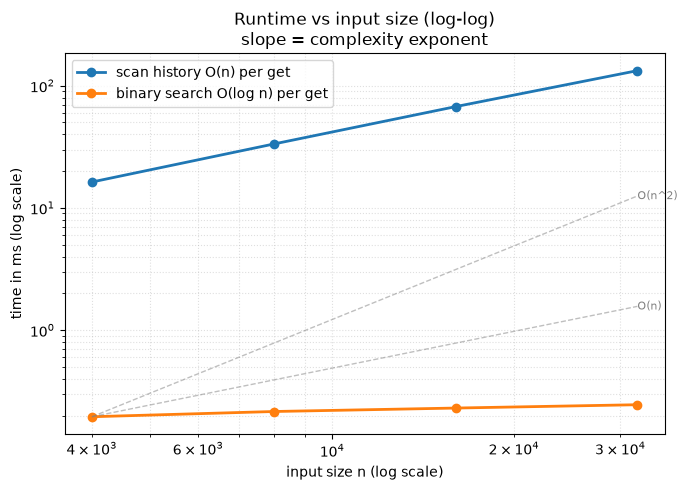

{'scan history O(n) per get': [16.285792109556496,
  33.323375042527914,
  67.37304199486971,
  132.7223340049386],
 'binary search O(log n) per get': [0.19558309577405453,
  0.21583400666713715,
  0.2303750952705741,
  0.24529092479497194]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

QUERIES = list(range(200))                    # 200 gets per timed run, all near the start of the history

def make_worst_case(n):
    history = [(t, f"v{t}") for t in range(1, n + 1)]   # one key, n entries, sorted by time
    return (history,)

def gets_with(cls):
    def run(history):
        tm = cls()
        tm.store["k"] = history               # preload: only get() is timed
        for t in QUERIES:
            tm.get("k", t)
    return run

solutions = {
    "scan history O(n) per get": gets_with(TimeMapBrute),
    "binary search O(log n) per get": gets_with(TimeMap),
}
sizes = [4_000, 8_000, 16_000, 32_000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Sorted Search](README.md) — the template in its boundary form: on `times[mid] <= t`, record a candidate and move `lo = mid + 1`; the last candidate recorded is the latest time `<= t`.
- **Sorted for free:** appending timestamps that only ever increase keeps each list sorted, so there is no sort cost before searching.
- **Hash map of lists:** a `dict` from key to history isolates each key's search to its own entries.
- **Library form:** `i = bisect.bisect_right(times, t) - 1`, answer `values[i]` if `i >= 0` (needs a separate list of times, or a key function).
- **Signal:** "value at time `t`", "most recent version at or before", "snapshot", "latest entry `<= x`".
- **Related problems:** Binary Search, Snapshot Array, Search Insert Position, Online Election, Stock Price Fluctuation.
- **Common pitfalls:**
  1. Stopping at the first `times[mid] <= t` instead of recording it and searching right — returns an earlier value than the latest.
  2. Returning `values[lo]` after the loop — when the loop ends, `lo` points one **past** the answer.
  3. `self.store[key]` on an unknown key with a `defaultdict` inside `get` — silently creates empty entries; use `.get(key, [])`.
  4. Re-sorting on every `set` — unnecessary, the timestamps already arrive in order.